# Replikation der Cluster: Discovery ↔ Validation

**Frage:** Finden wir die Clustertypen aus Discovery in der unabhängigen Validation-Stichprobe wieder?

**Vorgehen** (im Sinne von Hennig & Liao 2013: Cluster über die Verteilungen der Originalvariablen beschreiben):
1. Für jedes Cluster und jede gemeinsame Variable die **Verteilung der Antworten** (gewichtete Anteile je Kategorie).
2. Für jedes Paar aus D- und V-Cluster vergleichen, wie ähnlich diese Verteilungen sind (**Total Variation Distance**).
3. Jedem D-Cluster das ähnlichste V-Cluster zuordnen.

## Schritt 0: Daten laden
Imputierte Daten, Surveygewichte `wichtn`, GMM-Labels.

In [1]:
import ast
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

project_path = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
os.chdir(project_path)
sys.path.insert(0, str(project_path))

from utils.saving_utils import DatasetBundle

output_folder = Path("outputs/cluster_replication")
output_folder.mkdir(parents=True, exist_ok=True)

# Imputierte Daten: dieselben Daten (und Variablen), auf denen das Clustering beruht
data_discov = DatasetBundle.load(Path("data/imputed/data_discov_imputed"))
data_valid = DatasetBundle.load(Path("data/imputed/data_valid_imputed"))
D_raw = data_discov.data.reset_index(drop=True)
V_raw = data_valid.data.reset_index(drop=True)

# Surveygewichte aus den vollständigen Daten (gleiche Personen in gleicher Reihenfolge)
w_D = pd.to_numeric(DatasetBundle.load(Path("data/preprocessed/data_discov_full")).data["wichtn"]).to_numpy(dtype=float)
w_V = pd.to_numeric(DatasetBundle.load(Path("data/preprocessed/data_valid_full")).data["wichtn"]).to_numpy(dtype=float)

lab_D = pd.read_parquet("outputs/gmm_clustering/cluster_pred_discov.parquet")["label"].astype(str).to_numpy()
lab_V = pd.read_parquet("outputs/gmm_clustering/cluster_pred_valid.parquet")["label"].astype(str).to_numpy()

def sort_clusters(cs):
    return sorted(cs, key=lambda c: int(c) if str(c).isdigit() else str(c))

# Clustergrößen: n = Personen, Anteil = gewichtet (werden in Schritt 2 und 3 gebraucht)
def sizes(labels, w):
    s = pd.DataFrame({"n": pd.Series(labels).value_counts(),
                      "anteil_gew": pd.Series(w).groupby(labels).sum() / w.sum()})
    return s.loc[sort_clusters(s.index)]

size_D, size_V = sizes(lab_D, w_D), sizes(lab_V, w_V)

Loaded dataset from data/imputed/data_discov_imputed.
Loaded dataset from data/imputed/data_valid_imputed.
Loaded dataset from data/preprocessed/data_discov_full.
Loaded dataset from data/preprocessed/data_valid_full.


## Schritt 1: Gemeinsame Variablen und ihre Verteilungen
- Verwendet werden nur Variablen, die in **beiden** Stichproben erhoben sind. Die übrigen werden aufgelistet (z. B. `dsm_*`).
- Binäre, nominale und ordinale Variablen bleiben, wie sie sind: Jede Kategorie bekommt ihren Anteil. Wertelabels aus den Metadaten (z. B. *ja/nein*) werden übernommen.
- Kontinuierliche Variablen werden in Klassen eingeteilt: **0** und drei gleich große Gruppen der Werte > 0 (Grenzen aus beiden Stichproben gemeinsam).
- Anteile sind **gewichtet** und beziehen sich auf **Personen mit gültiger Angabe**.

In [2]:
# ------------------------------------------------------------
# Gemeinsame Variablen und Kategorien
# Jede Variable wird als Verteilung über ihre Kategorien betrachtet.
# Kontinuierliche Variablen werden dafür in Klassen eingeteilt (0 und Terzile der Werte > 0).
# ------------------------------------------------------------
EXCLUDE = ["wichtn", "lfd", "fall"]

meta = data_discov.meta.set_index("name")
vtype = meta["type"]

# Clustering-Variablen, die in beiden imputierten Datensätzen vorkommen
shared = [v for v in meta.index if v not in EXCLUDE and v in D_raw.columns and v in V_raw.columns]
not_shared = sorted((set(D_raw.columns) ^ set(V_raw.columns)) - set(EXCLUDE))

print(f"{len(shared)} Variablen in beiden Datensätzen, {len(not_shared)} nur in einem:")
print(not_shared)

def value_labels(v):
    """Wertelabels aus den Metadaten (falls vorhanden), z. B. {0: 'nein', 1: 'ja'}."""
    if "labels" in meta.columns and isinstance(meta.at[v, "labels"], str):
        try:
            return {str(k): str(lab) for k, lab in ast.literal_eval(meta.at[v, "labels"]).items()}
        except (ValueError, SyntaxError):
            pass
    return {}

def categorize(v):
    """Beide Datensätze in dieselben Kategorien überführen (als Text)."""
    if vtype[v] == "continuous":
        xd, xv = pd.to_numeric(D_raw[v], errors="coerce"), pd.to_numeric(V_raw[v], errors="coerce")
        pos = pd.concat([xd, xv])
        pos = pos[pos > 0]
        if pos.nunique() < 3:
            cuts = [0, np.inf]
        else:
            q1, q2 = np.quantile(pos, [1 / 3, 2 / 3])
            cuts = [0, q1, q2, np.inf]
        names = ["0"] + [f"{a:.4g}–{b:.4g}" if np.isfinite(b) else f">{a:.4g}" for a, b in zip(cuts[:-1], cuts[1:])]
        def cut(x):
            out = pd.Series(pd.NA, index=x.index, dtype="string")
            out[x == 0] = "0"
            for name, a, b in zip(names[1:], cuts[:-1], cuts[1:]):
                out[(x > a) & (x <= b)] = name
            return out
        return cut(xd), cut(xv)
    labels = value_labels(v)
    conv = lambda s: s.astype("string").map(lambda c: labels.get(c, c) if pd.notna(c) else pd.NA)
    return conv(D_raw[v]), conv(V_raw[v])

cats = {v: categorize(v) for v in shared}

def distributions(series, labels, w):
    """Gewichtete Anteile je Kategorie und Cluster."""
    ok = series.notna().to_numpy()
    df = pd.DataFrame({"cat": series[ok].to_numpy(), "cl": labels[ok], "w": w[ok]})
    tab = df.pivot_table(index="cl", columns="cat", values="w", aggfunc="sum", fill_value=0)
    total = df.groupby("cat")["w"].sum()
    return tab.div(tab.sum(axis=1), axis=0), total / total.sum()

dist = {}
for v, (sd, sv) in cats.items():
    pD, totD = distributions(sd, lab_D, w_D)
    pV, totV = distributions(sv, lab_V, w_V)
    allcats = pD.columns.union(pV.columns)
    dist[v] = (pD.reindex(columns=allcats, fill_value=0), pV.reindex(columns=allcats, fill_value=0),
               totD.reindex(allcats, fill_value=0))

38 Variablen in beiden Datensätzen, 24 nur in einem:
['audit', 'dsm_au', 'dsm_au_m', 'dsm_ber', 'dsm_ber_m', 'dsm_ha', 'dsm_ha_m', 'dsm_kc', 'dsm_kc_m', 'dsm_schl', 'dsm_schl_m', 'dsm_ta', 'fag_sch', 'fr12_meth1', 'harmf', 'hazar', 'hnb_fag_sch', 'pomi', 'psecdi_sch', 'rist', 'rist_noa', 'sds_a', 'sds_c', 'sds_k']


## Schritt 2: Abstand zwischen Clustern und Zuordnung

**Total Variation Distance (TVD)** für eine Variable:

TVD = ½ · Σ |Anteil im D-Cluster − Anteil im V-Cluster| (über alle Kategorien)

→ Anteil der Personen, der die Kategorie wechseln müsste, damit beide Verteilungen gleich sind. **0 = identisch, 1 = keinerlei Überschneidung.**

Der Abstand eines Clusterpaars ist der **Mittelwert der TVD über alle gemeinsamen Variablen** (jede Variable zählt einmal).

In der Tabelle:
- `bestes_V` / `TVD`: ähnlichstes Validation-Cluster und sein Abstand
- `zweitbestes_V` / `TVD_2`: zum Vergleich. Großer Abstand zwischen `TVD` und `TVD_2` = eindeutige Zuordnung
- `gegenseitig`: Ist das D-Cluster umgekehrt auch das ähnlichste für dieses V-Cluster? `True` = stärkste Form der Replikation

Zusätzlich: Validation-Cluster, die für kein D-Cluster das beste Gegenstück sind (= Typen, die es nur in Validation gibt).

In [3]:
# ------------------------------------------------------------
# Abstand zwischen zwei Clustern: Total Variation Distance (TVD) je Variable
#   TVD = 1/2 * Summe |Anteil im D-Cluster - Anteil im V-Cluster| über alle Kategorien
#   = Anteil der Personen, der die Kategorie wechseln müsste, damit beide Verteilungen gleich sind
#   0 = identische Verteilung, 1 = keinerlei Überschneidung
# Gesamtabstand eines Clusterpaars = Mittelwert der TVD über alle gemeinsamen Variablen
# ------------------------------------------------------------
cl_D, cl_V = list(size_D.index), list(size_V.index)
tvd = {}   # tvd[v] = DataFrame D x V
for v, (pD, pV, _) in dist.items():
    m = pd.DataFrame(index=cl_D, columns=cl_V, dtype=float)
    for d in cl_D:
        for c in cl_V:
            if d in pD.index and c in pV.index:
                m.loc[d, c] = 0.5 * np.abs(pD.loc[d] - pV.loc[c]).sum()
    tvd[v] = m

tvd_mean = sum(m.fillna(0) for m in tvd.values()) / sum(m.notna().astype(int) for m in tvd.values())
tvd_mean.to_csv(output_folder / "tvd_mittel_D_x_V.csv")

# Zuordnung: für jedes Cluster das ähnlichste Gegenstück in der anderen Stichprobe
best_V = tvd_mean.idxmin(axis=1)
best_D = tvd_mean.idxmin(axis=0)

rows = []
for d in cl_D:
    r = tvd_mean.loc[d].sort_values()
    rows.append({
        "D": d, "n_D": size_D.at[d, "n"], "anteil_D": size_D.at[d, "anteil_gew"],
        "bestes_V": r.index[0], "n_V": size_V.at[r.index[0], "n"], "TVD": r.iloc[0],
        "zweitbestes_V": r.index[1], "TVD_2": r.iloc[1],
        "gegenseitig": best_D[r.index[0]] == d,   # ist D auch für dieses V das beste Gegenstück?
    })
matching = pd.DataFrame(rows).set_index("D").sort_values("n_D", ascending=False)

print("Zuordnung Discovery → Validation (mittlere TVD, 0 = identisch):")
display(matching.round(3))

unmatched_V = [c for c in cl_V if c not in set(best_V)]
print("Validation-Cluster, die für kein Discovery-Cluster das beste Gegenstück sind:", unmatched_V)
matching.to_csv(output_folder / "zuordnung_D_V.csv")

Zuordnung Discovery → Validation (mittlere TVD, 0 = identisch):


,n_D,anteil_D,bestes_V,n_V,TVD,zweitbestes_V,TVD_2,gegenseitig
D,,,,,,,,
0,2858,0.300,0,3319,0.023,3,0.082,True
1,1893,0.231,1,1426,0.017,2,0.152,True
2,1226,0.152,0,3319,0.035,3,0.089,False
3,1199,0.128,3,949,0.069,4,0.080,True
4,627,0.075,2,1117,0.022,4,0.097,True
5,335,0.038,5,590,0.044,4,0.073,True
6,273,0.028,6,365,0.051,5,0.100,True
8,190,0.018,5,590,0.096,6,0.097,False
7,170,0.022,2,1117,0.059,4,0.129,False


Validation-Cluster, die für kein Discovery-Cluster das beste Gegenstück sind: ['7', '8', '9', '10']


## Schritt 3: Abbildung – Übereinstimmung aller Clusterpaare
Werte = 1 − mittlere TVD (1 = identische Profile). Zeilen: Discovery nach Größe. Spalten: Validation in der Reihenfolge der Zuordnung, sodass gute Paare auf der Diagonalen liegen. Der **orange Rahmen** markiert pro Zeile das beste Gegenstück.

So liest man sie:
- dunkles Feld auf der Diagonalen, helle Nachbarn → eindeutig repliziert
- zwei Zeilen mit demselben Spalten-Rahmen → zwei D-Cluster fallen in Validation zusammen
- Spalten ganz rechts ohne Rahmen → Typen nur in Validation

In [ ]:
# ------------------------------------------------------------
# Abbildung: Ähnlichkeit aller Clusterpaare (1 - mittlere TVD)
# Zeilen: Discovery D0–D10; Spalten: Validation in der Reihenfolge der Zuordnung
# ------------------------------------------------------------
SHOW_VALUES = True     # False = keine Zahlen in den Zellen, nur Farben

rows_order = cl_D                                                     # D0, D1, ..., D10
cols_order = list(dict.fromkeys([best_V[d] for d in rows_order])) + [c for c in cl_V if c not in set(best_V)]
sim = (1 - tvd_mean).loc[rows_order, cols_order]
vmin = sim.min().min()

fig, ax = plt.subplots(figsize=(1.0 + 0.55 * len(cols_order), 1.0 + 0.45 * len(rows_order)))
im = ax.imshow(sim.to_numpy(dtype=float), cmap="Blues", vmin=vmin, vmax=1, aspect="auto")
if SHOW_VALUES:
    for i in range(len(rows_order)):
        for j in range(len(cols_order)):
            val = sim.iat[i, j]
            ax.text(j, i, f"{val:.2f}", ha="center", va="center", fontsize=7,
                    color="white" if val > vmin + 0.6 * (1 - vmin) else "#333333")
ax.set_xticks(range(len(cols_order)))
ax.set_xticklabels([f"V{c}" for c in cols_order], fontsize=8)
ax.set_yticks(range(len(rows_order)))
ax.set_yticklabels([f"D{d}" for d in rows_order], fontsize=8)
ax.set_xlabel("Validation-Cluster")
ax.set_ylabel("Discovery-Cluster")
ax.set_title("Übereinstimmung der Clusterprofile (1 − mittlere TVD)")
fig.colorbar(im, ax=ax, label="Übereinstimmung")
plt.tight_layout()
plt.savefig(output_folder / "uebereinstimmung_D_V.png", dpi=300, bbox_inches="tight")
plt.show()

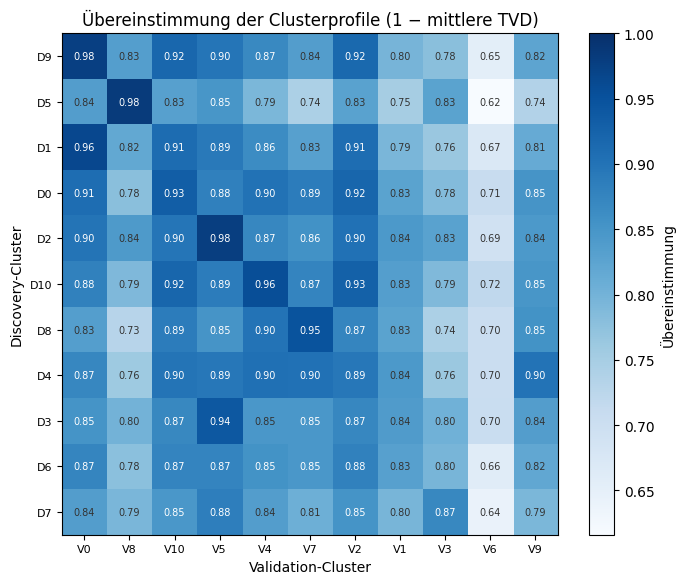

In [ ]:
# ------------------------------------------------------------
# Abbildung: Ähnlichkeit aller Clusterpaare (1 - mittlere TVD)
# Zeilen: Discovery nach Größe; Spalten: Validation in der Reihenfolge der Zuordnung
# ------------------------------------------------------------
SHOW_VALUES = True     # False = keine Zahlen in den Zellen, nur Farben

rows_order = list(matching.index)                                     # Discovery nach Größe
cols_order = list(dict.fromkeys([best_V[d] for d in rows_order])) + [c for c in cl_V if c not in set(best_V)]
sim = (1 - tvd_mean).loc[rows_order, cols_order]
vmin = sim.min().min()

fig, ax = plt.subplots(figsize=(1.0 + 0.55 * len(cols_order), 1.0 + 0.45 * len(rows_order)))
im = ax.imshow(sim.to_numpy(dtype=float), cmap="Blues", vmin=vmin, vmax=1, aspect="auto")
if SHOW_VALUES:
    for i in range(len(rows_order)):
        for j in range(len(cols_order)):
            val = sim.iat[i, j]
            ax.text(j, i, f"{val:.2f}", ha="center", va="center", fontsize=7,
                    color="white" if val > vmin + 0.6 * (1 - vmin) else "#333333")
ax.set_xticks(range(len(cols_order)))
ax.set_xticklabels([f"V{c}" for c in cols_order], fontsize=8)
ax.set_yticks(range(len(rows_order)))
ax.set_yticklabels([f"D{d}" for d in rows_order], fontsize=8)
ax.set_xlabel("Validation-Cluster")
ax.set_ylabel("Discovery-Cluster")
ax.set_title("Übereinstimmung der Clusterprofile (1 − mittlere TVD)")
fig.colorbar(im, ax=ax, label="Übereinstimmung")
plt.tight_layout()
plt.savefig(output_folder / "uebereinstimmung_D_V.png", dpi=300, bbox_inches="tight")
plt.show()

## Schritt 4: Ein Paar im Detail
Trage bei `PAIR` ein Paar ein (z. B. `("9", "0")` für D9 und V0). Die Tabelle zeigt die Variablen mit den **größten Unterschieden** zwischen den beiden Clustern, mit allen Kategorien-Anteilen und dem Gesamtschnitt. Damit siehst du, *worin* sich ein gematchtes Paar trotzdem unterscheidet.

In [ ]:
# ------------------------------------------------------------
# Ein Clusterpaar im Detail: Wo stimmen D und V überein, wo nicht?
# ------------------------------------------------------------
def compare_pair(d, v, top=10):
    """Variablen mit den größten Unterschieden zwischen D-Cluster d und V-Cluster v."""
    diff = pd.Series({var: tvd[var].loc[d, v] for var in tvd}).sort_values(ascending=False)
    print(f"D{d} vs. V{v}: mittlere TVD = {tvd_mean.loc[d, v]:.3f}")
    print(f"Größte Unterschiede (TVD je Variable):")
    rows = []
    for var in diff.index[:top]:
        pD, pV, tot = dist[var]
        for cat in pD.columns:
            rows.append({"variable": var, "kategorie": cat, f"D{d} %": 100 * pD.loc[d, cat],
                         f"V{v} %": 100 * pV.loc[v, cat], "gesamt D %": 100 * tot[cat], "TVD": diff[var]})
    table = pd.DataFrame(rows).set_index(["variable", "kategorie"])
    display(table.round({c: 1 for c in table.columns if c != "TVD"} | {"TVD": 3}))
    return diff

PAIR = ("5", "6")      # hier das Paar eintragen, das du zeigen willst
_ = compare_pair(*PAIR)

D5 vs. V6: mittlere TVD = 0.384
Größte Unterschiede (TVD je Variable):


D5 %  V6 %  \
variable kategorie                                                         
fr12_ha1 (Fast) täglich                                        0.0   0.0   
         Gar nicht                                           100.0   0.0   
         Mindestens einmal im Monat                            0.0  30.1   
         Mindestens einmal pro Woche                           0.0   0.0   
         Seltener als einmal im Monat                          0.0  69.9   
ber_kat  0x letzte 30 Tage                                   100.0   0.0   
         mind. 1x pro Woche/letzte 30 Tage                     0.0  57.9   
         mind. 1x/letzte 30 Tage                               0.0  42.1   
         t?glich/letzte 30 Tage                                0.0   0.0   
vx210    lebenslang abstinent                                 13.1   0.0   
         letzte 12 Monate, nicht letzte 30 Tage               54.5  12.0   
         letzte 30 Tage                                        0.0  88.0   
         länger als 12 Monate                                 32.4   0.0   
alk30kat 0                                                   100.0  12.0   
         gef?hrlicher Konsum / Hochkonsum                      0.0  15.7   
         risikoarmer Konsum                                    0.0  72.3   
         riskanter Konsum                                      0.0   0.0   
bier30gr 0                                                   100.0  12.0   
         0–2.033                                               0.0   0.0   
         2.033–7.622                                           0.0  42.2   
         >7.622                                                0.0  45.8   
bierkons ja                                                    0.0  88.0   
         nein                                                100.0  12.0   
fr12_he1 Gar nicht                                           100.0  12.0   
         Seltener als einmal im Monat / Mindestens einma...    0.0  88.0   
spirkons ja                                                    0.0  88.0   
         nein                                                100.0  12.0   
binge    1-3mal letzte 30 Tage                                 0.0  42.2   
         mind. 4x letzte 30 Tage                               0.0  45.8   
         nie                                                 100.0  12.0   
fr12_ao1 Gar nicht                                           100.0  15.7   
         Seltener als einmal im Monat / Mindestens einma...    0.0  84.3   

                                                             gesamt D %    TVD  
variable kategorie                                                              
fr12_ha1 (Fast) täglich                                             0.8  1.000  
         Gar nicht                                                 93.7  1.000  
         Mindestens einmal im Monat                                 0.7  1.000  
         Mindestens einmal pro Woche                                0.7  1.000  
         Seltener als einmal im Monat                               4.1  1.000  
ber_kat  0x letzte 30 Tage                                         97.8  1.000  
         mind. 1x pro Woche/letzte 30 Tage                          0.7  1.000  
         mind. 1x/letzte 30 Tage                                    0.8  1.000  
         t?glich/letzte 30 Tage                                     0.7  1.000  
vx210    lebenslang abstinent                                       3.5  0.880  
         letzte 12 Monate, nicht letzte 30 Tage                    15.3  0.880  
         letzte 30 Tage                                            71.7  0.880  
         länger als 12 Monate                                       9.5  0.880  
alk30kat 0                                                         28.3  0.880  
         gef?hrlicher Konsum / Hochkonsum                           1.5  0.880  
         risikoarmer Konsum                                        64.6  0.880  
         riskanter 

## Schritt 5: Folienbild für ein Paar

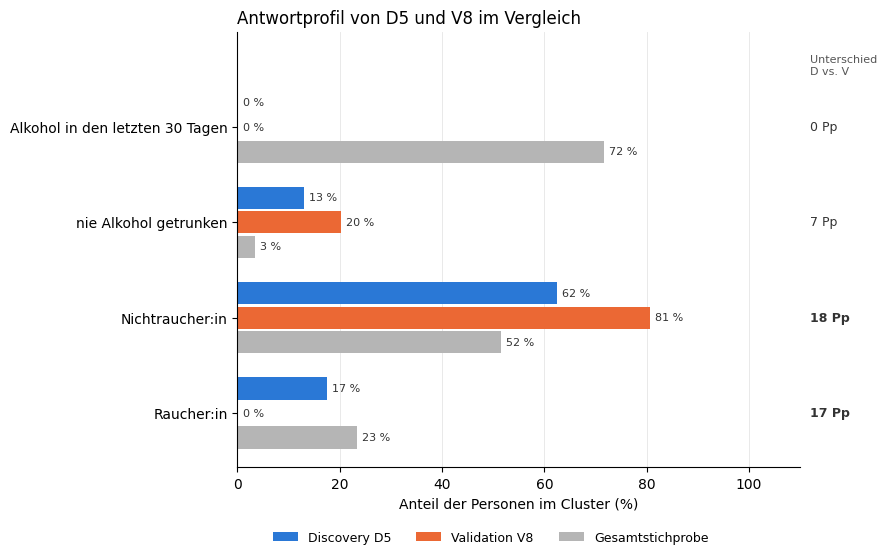

,D,V,gesamt
merkmal,,,
Alkohol in den letzten 30 Tagen,0.0,0.0,71.7
nie Alkohol getrunken,13.1,20.3,3.5
Nichtraucher:in,62.4,80.6,51.5
Raucher:in,17.4,0.0,23.3


In [ ]:
# ------------------------------------------------------------
# Folienbild: ein Clusterpaar, ausgewählte Merkmale
# Pro Merkmal drei Balken: Discovery-Cluster, Validation-Cluster, Gesamtstichprobe
# Rechts: Unterschied zwischen D und V in Prozentpunkten
# ------------------------------------------------------------
PAIR = ("5", "8")

# (Variable, Kategorie) genau wie in der Tabelle aus Schritt 4 – und eine verständliche Beschriftung
KEY_FEATURES = [
    ("vx210", "letzte 30 Tage",       "Alkohol in den letzten 30 Tagen"),
    ("vx210", "lebenslang abstinent", "nie Alkohol getrunken"),
    ("typ2",  "Nichtraucher",         "Nichtraucher:in"),
    ("typ2",  "Raucher",              "Raucher:in"),
]

COL_D, COL_V, COL_ALL = "#2a78d6", "#eb6834", "#b5b5b5"

def pair_bars(d, v, features):
    rows = []
    for var, cat, label in features:
        pD, pV, tot = dist[var]
        rows.append({"merkmal": label, "D": 100 * pD.loc[d, cat], "V": 100 * pV.loc[v, cat], "gesamt": 100 * tot[cat]})
    vals = pd.DataFrame(rows).set_index("merkmal")

    n = len(vals)
    y = np.arange(n)[::-1] * 1.4          # etwas Abstand zwischen den Merkmalen
    h = 0.36
    fig, ax = plt.subplots(figsize=(9, 1.1 * n + 1.3))
    for offset, col, key, name in [(h, COL_D, "D", f"Discovery D{d}"),
                                   (0, COL_V, "V", f"Validation V{v}"),
                                   (-h, COL_ALL, "gesamt", "Gesamtstichprobe")]:
        ax.barh(y + offset, vals[key], height=h * 0.9, color=col, label=name)
        for yi, val in zip(y + offset, vals[key]):
            ax.text(val + 1, yi, f"{val:.0f} %", va="center", fontsize=8, color="#333333")

    # Unterschied D vs. V rechts neben dem Diagramm
    for yi, a, b in zip(y, vals["D"], vals["V"]):
        diff = abs(a - b)
        ax.text(112, yi, f"{diff:.0f} Pp", va="center", ha="left", fontsize=9,
                color="#333333", fontweight="bold" if diff >= 10 else "normal")
    ax.text(112, y.max() + 0.75, "Unterschied\nD vs. V", va="bottom", ha="left", fontsize=8, color="#555555")
    ax.set_ylim(y.min() - 0.8, y.max() + 1.4)

    ax.set_yticks(y)
    ax.set_yticklabels(vals.index, fontsize=10)
    ax.set_xlim(0, 110)
    ax.set_xlabel("Anteil der Personen im Cluster (%)")
    ax.set_title(f"Antwortprofil von D{d} und V{v} im Vergleich", loc="left", fontsize=12)
    ax.grid(axis="x", color="#e5e5e5", lw=0.6)
    ax.set_axisbelow(True)
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)
    ax.legend(frameon=False, fontsize=9, loc="upper center", bbox_to_anchor=(0.45, -0.12), ncol=3)
    plt.tight_layout()
    plt.savefig(output_folder / f"paar_D{d}_V{v}.png", dpi=300, bbox_inches="tight")
    plt.show()
    return vals

display(pair_bars(*PAIR, KEY_FEATURES).round(1))

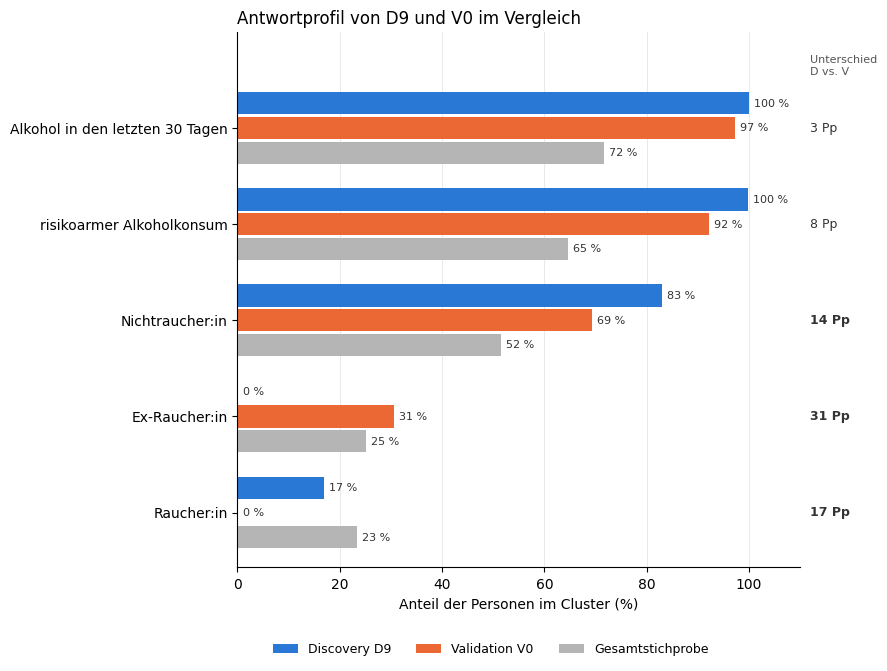

,D,V,gesamt
merkmal,,,
Alkohol in den letzten 30 Tagen,100.0,97.2,71.7
risikoarmer Alkoholkonsum,99.8,92.2,64.6
Nichtraucher:in,83.1,69.4,51.5
Ex-Raucher:in,0.0,30.6,25.2
Raucher:in,16.9,0.0,23.3


In [ ]:
# ------------------------------------------------------------
# Folienbild: ein Clusterpaar, ausgewählte Merkmale
# Pro Merkmal drei Balken: Discovery-Cluster, Validation-Cluster, Gesamtstichprobe
# Rechts: Unterschied zwischen D und V in Prozentpunkten
# ------------------------------------------------------------
PAIR = ("9", "0")

KEY_FEATURES = [
    ("vx210",    "letzte 30 Tage",     "Alkohol in den letzten 30 Tagen"),
    ("alk30kat", "risikoarmer Konsum", "risikoarmer Alkoholkonsum"),
    ("typ2",     "Nichtraucher",       "Nichtraucher:in"),
    ("typ2",     "Exraucher",          "Ex-Raucher:in"),
    ("typ2",     "Raucher",            "Raucher:in"),
]

COL_D, COL_V, COL_ALL = "#2a78d6", "#eb6834", "#b5b5b5"

def pair_bars(d, v, features):
    rows = []
    for var, cat, label in features:
        pD, pV, tot = dist[var]
        rows.append({"merkmal": label, "D": 100 * pD.loc[d, cat], "V": 100 * pV.loc[v, cat], "gesamt": 100 * tot[cat]})
    vals = pd.DataFrame(rows).set_index("merkmal")

    n = len(vals)
    y = np.arange(n)[::-1] * 1.4          # etwas Abstand zwischen den Merkmalen
    h = 0.36
    fig, ax = plt.subplots(figsize=(9, 1.1 * n + 1.3))
    for offset, col, key, name in [(h, COL_D, "D", f"Discovery D{d}"),
                                   (0, COL_V, "V", f"Validation V{v}"),
                                   (-h, COL_ALL, "gesamt", "Gesamtstichprobe")]:
        ax.barh(y + offset, vals[key], height=h * 0.9, color=col, label=name)
        for yi, val in zip(y + offset, vals[key]):
            ax.text(val + 1, yi, f"{val:.0f} %", va="center", fontsize=8, color="#333333")

    # Unterschied D vs. V rechts neben dem Diagramm
    for yi, a, b in zip(y, vals["D"], vals["V"]):
        diff = abs(a - b)
        ax.text(112, yi, f"{diff:.0f} Pp", va="center", ha="left", fontsize=9,
                color="#333333", fontweight="bold" if diff >= 10 else "normal")
    ax.text(112, y.max() + 0.75, "Unterschied\nD vs. V", va="bottom", ha="left", fontsize=8, color="#555555")
    ax.set_ylim(y.min() - 0.8, y.max() + 1.4)

    ax.set_yticks(y)
    ax.set_yticklabels(vals.index, fontsize=10)
    ax.set_xlim(0, 110)
    ax.set_xlabel("Anteil der Personen im Cluster (%)")
    ax.set_title(f"Antwortprofil von D{d} und V{v} im Vergleich", loc="left", fontsize=12)
    ax.grid(axis="x", color="#e5e5e5", lw=0.6)
    ax.set_axisbelow(True)
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)
    ax.legend(frameon=False, fontsize=9, loc="upper center", bbox_to_anchor=(0.45, -0.12), ncol=3)
    plt.tight_layout()
    plt.savefig(output_folder / f"paar_D{d}_V{v}.png", dpi=300, bbox_inches="tight")
    plt.show()
    return vals

display(pair_bars(*PAIR, KEY_FEATURES).round(1))

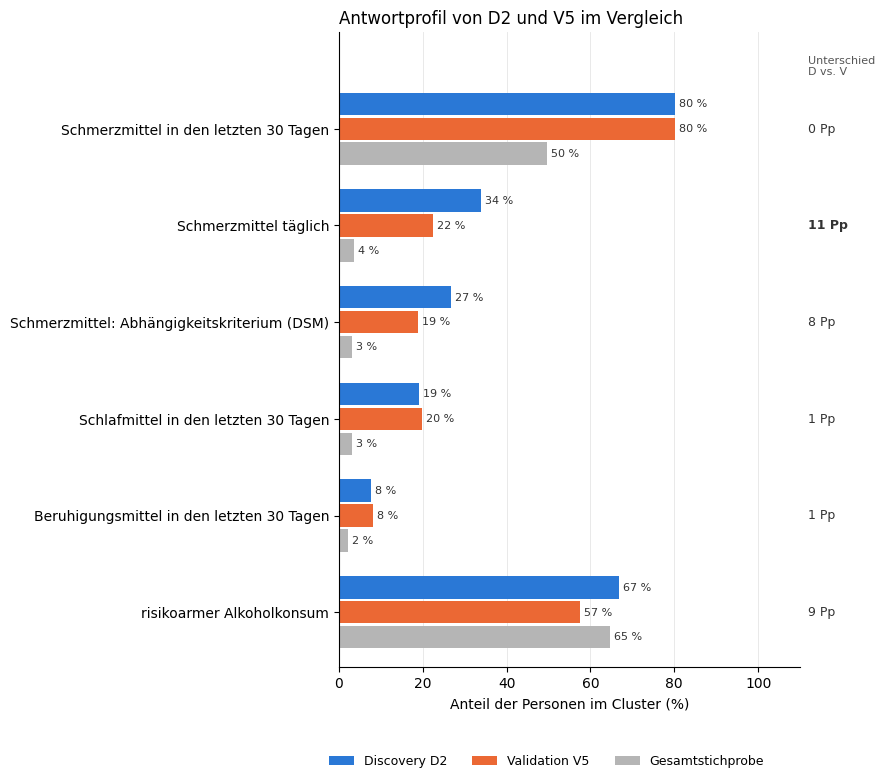

,D,V,gesamt
merkmal,,,
Schmerzmittel in den letzten 30 Tagen,80.2,80.1,49.6
Schmerzmittel täglich,33.9,22.5,3.5
Schmerzmittel: Abhängigkeitskriterium (DSM),26.7,18.8,3.1
Schlafmittel in den letzten 30 Tagen,19.0,19.9,3.1
Beruhigungsmittel in den letzten 30 Tagen,7.6,8.2,2.2
risikoarmer Alkoholkonsum,66.8,57.5,64.6


In [ ]:
# ------------------------------------------------------------
# Folienbild: ein Clusterpaar, ausgewählte Merkmale
# Pro Merkmal drei Balken: Discovery-Cluster, Validation-Cluster, Gesamtstichprobe
# Rechts: Unterschied zwischen D und V in Prozentpunkten
# ------------------------------------------------------------
PAIR = ("2", "5")

# (Variable, Kategorie, Beschriftung)
#   Kategorie genau wie in der Tabelle aus Schritt 4, oder ein eindeutiger Teil davon (z. B. "glich" für "täglich")
#   "!" davor = alle anderen Kategorien zusammen, z. B. "!0x letzte 30 Tage" = mindestens einmal in 30 Tagen
KEY_FEATURES = [
    ("schm_kat", "!0x letzte 30 Tage", "Schmerzmittel in den letzten 30 Tagen"),
    ("schm_kat", "glich/letzte 30 Tage", "Schmerzmittel täglich"),
    ("dsm_schm", "ja",                 "Schmerzmittel: Abhängigkeitskriterium (DSM)"),
    ("schl_kat", "!0x letzte 30 Tage", "Schlafmittel in den letzten 30 Tagen"),
    ("ber_kat",  "!0x letzte 30 Tage", "Beruhigungsmittel in den letzten 30 Tagen"),
    ("alk30kat", "risikoarmer Konsum", "risikoarmer Alkoholkonsum"),
]

COL_D, COL_V, COL_ALL = "#2a78d6", "#eb6834", "#b5b5b5"

def resolve(var, cat):
    """Kategorie finden: exakter Name, sonst eindeutiger Teil des Namens (hilft bei Umlaut-Problemen wie 't?glich')."""
    cols = list(dist[var][0].columns)
    if cat in cols:
        return cat
    hits = [c for c in cols if cat in str(c)]
    if len(hits) != 1:
        raise KeyError(f"{var}: Kategorie '{cat}' nicht eindeutig gefunden. Vorhanden: {cols}")
    return hits[0]

def share(var, cat, d, v):
    """Anteile (%) für D-Cluster, V-Cluster und gesamt. '!' vor der Kategorie = alle ANDEREN Kategorien zusammen."""
    pD, pV, tot = dist[var]
    neg = cat.startswith("!")
    c = resolve(var, cat[1:] if neg else cat)
    vals = 100 * np.array([pD.loc[d, c], pV.loc[v, c], tot[c]])
    return 100 - vals if neg else vals

def pair_bars(d, v, features):
    rows = []
    for var, cat, label in features:
        sD, sV, sAll = share(var, cat, d, v)
        rows.append({"merkmal": label, "D": sD, "V": sV, "gesamt": sAll})
    vals = pd.DataFrame(rows).set_index("merkmal")

    n = len(vals)
    y = np.arange(n)[::-1] * 1.4          # etwas Abstand zwischen den Merkmalen
    h = 0.36
    fig, ax = plt.subplots(figsize=(9, 1.1 * n + 1.3))
    for offset, col, key, name in [(h, COL_D, "D", f"Discovery D{d}"),
                                   (0, COL_V, "V", f"Validation V{v}"),
                                   (-h, COL_ALL, "gesamt", "Gesamtstichprobe")]:
        ax.barh(y + offset, vals[key], height=h * 0.9, color=col, label=name)
        for yi, val in zip(y + offset, vals[key]):
            ax.text(val + 1, yi, f"{val:.0f} %", va="center", fontsize=8, color="#333333")

    # Unterschied D vs. V rechts neben dem Diagramm
    for yi, a, b in zip(y, vals["D"], vals["V"]):
        diff = abs(a - b)
        ax.text(112, yi, f"{diff:.0f} Pp", va="center", ha="left", fontsize=9,
                color="#333333", fontweight="bold" if diff >= 10 else "normal")
    ax.text(112, y.max() + 0.75, "Unterschied\nD vs. V", va="bottom", ha="left", fontsize=8, color="#555555")
    ax.set_ylim(y.min() - 0.8, y.max() + 1.4)

    ax.set_yticks(y)
    ax.set_yticklabels(vals.index, fontsize=10)
    ax.set_xlim(0, 110)
    ax.set_xlabel("Anteil der Personen im Cluster (%)")
    ax.set_title(f"Antwortprofil von D{d} und V{v} im Vergleich", loc="left", fontsize=12)
    ax.grid(axis="x", color="#e5e5e5", lw=0.6)
    ax.set_axisbelow(True)
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)
    ax.legend(frameon=False, fontsize=9, loc="upper center", bbox_to_anchor=(0.45, -0.12), ncol=3)
    plt.tight_layout()
    plt.savefig(output_folder / f"paar_D{d}_V{v}.png", dpi=300, bbox_inches="tight")
    plt.show()
    return vals

display(pair_bars(*PAIR, KEY_FEATURES).round(1))

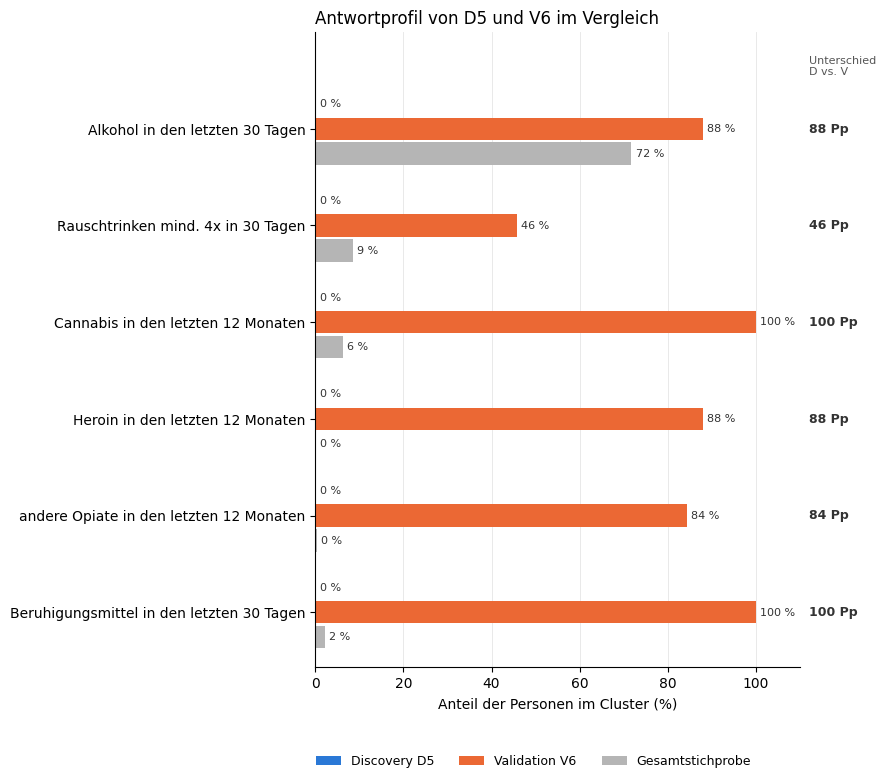

,D,V,gesamt
merkmal,,,
Alkohol in den letzten 30 Tagen,0.0,88.0,71.7
Rauschtrinken mind. 4x in 30 Tagen,0.0,45.8,8.5
Cannabis in den letzten 12 Monaten,0.0,100.0,6.3
Heroin in den letzten 12 Monaten,0.0,88.0,0.0
andere Opiate in den letzten 12 Monaten,0.0,84.3,0.4
Beruhigungsmittel in den letzten 30 Tagen,0.0,100.0,2.2


In [ ]:
# ------------------------------------------------------------
# Folienbild: ein Clusterpaar, ausgewählte Merkmale
# Pro Merkmal drei Balken: Discovery-Cluster, Validation-Cluster, Gesamtstichprobe
# Rechts: Unterschied zwischen D und V in Prozentpunkten
# ------------------------------------------------------------
PAIR = ("5", "6")

# (Variable, Kategorie, Beschriftung)
#   Kategorie genau wie in der Tabelle aus Schritt 4, oder ein eindeutiger Teil davon (z. B. "glich" für "täglich")
#   "!" davor = alle anderen Kategorien zusammen, z. B. "!Gar nicht" = mindestens einmal genommen
KEY_FEATURES = [
    ("vx210",    "letzte 30 Tage",     "Alkohol in den letzten 30 Tagen"),
    ("binge",    "mind. 4x",           "Rauschtrinken mind. 4x in 30 Tagen"),
    ("fr12_ha1", "!Gar nicht",         "Cannabis in den letzten 12 Monaten"),
    ("fr12_he1", "!Gar nicht",         "Heroin in den letzten 12 Monaten"),
    ("fr12_ao1", "!Gar nicht",         "andere Opiate in den letzten 12 Monaten"),
    ("ber_kat",  "!0x letzte 30 Tage", "Beruhigungsmittel in den letzten 30 Tagen"),
]

COL_D, COL_V, COL_ALL = "#2a78d6", "#eb6834", "#b5b5b5"

def resolve(var, cat):
    """Kategorie finden: exakter Name, sonst eindeutiger Teil des Namens (hilft bei Umlaut-Problemen wie 't?glich')."""
    cols = list(dist[var][0].columns)
    if cat in cols:
        return cat
    hits = [c for c in cols if cat in str(c)]
    if len(hits) != 1:
        raise KeyError(f"{var}: Kategorie '{cat}' nicht eindeutig gefunden. Vorhanden: {cols}")
    return hits[0]

def share(var, cat, d, v):
    """Anteile (%) für D-Cluster, V-Cluster und gesamt. '!' vor der Kategorie = alle ANDEREN Kategorien zusammen."""
    pD, pV, tot = dist[var]
    neg = cat.startswith("!")
    c = resolve(var, cat[1:] if neg else cat)
    vals = 100 * np.array([pD.loc[d, c], pV.loc[v, c], tot[c]])
    return 100 - vals if neg else vals

def pair_bars(d, v, features):
    rows = []
    for var, cat, label in features:
        sD, sV, sAll = share(var, cat, d, v)
        rows.append({"merkmal": label, "D": sD, "V": sV, "gesamt": sAll})
    vals = pd.DataFrame(rows).set_index("merkmal")

    n = len(vals)
    y = np.arange(n)[::-1] * 1.4          # etwas Abstand zwischen den Merkmalen
    h = 0.36
    fig, ax = plt.subplots(figsize=(9, 1.1 * n + 1.3))
    for offset, col, key, name in [(h, COL_D, "D", f"Discovery D{d}"),
                                   (0, COL_V, "V", f"Validation V{v}"),
                                   (-h, COL_ALL, "gesamt", "Gesamtstichprobe")]:
        ax.barh(y + offset, vals[key], height=h * 0.9, color=col, label=name)
        for yi, val in zip(y + offset, vals[key]):
            ax.text(val + 1, yi, f"{val:.0f} %", va="center", fontsize=8, color="#333333")

    # Unterschied D vs. V rechts neben dem Diagramm
    for yi, a, b in zip(y, vals["D"], vals["V"]):
        diff = abs(a - b)
        ax.text(112, yi, f"{diff:.0f} Pp", va="center", ha="left", fontsize=9,
                color="#333333", fontweight="bold" if diff >= 10 else "normal")
    ax.text(112, y.max() + 0.75, "Unterschied\nD vs. V", va="bottom", ha="left", fontsize=8, color="#555555")
    ax.set_ylim(y.min() - 0.8, y.max() + 1.4)

    ax.set_yticks(y)
    ax.set_yticklabels(vals.index, fontsize=10)
    ax.set_xlim(0, 110)
    ax.set_xlabel("Anteil der Personen im Cluster (%)")
    ax.set_title(f"Antwortprofil von D{d} und V{v} im Vergleich", loc="left", fontsize=12)
    ax.grid(axis="x", color="#e5e5e5", lw=0.6)
    ax.set_axisbelow(True)
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)
    ax.legend(frameon=False, fontsize=9, loc="upper center", bbox_to_anchor=(0.45, -0.12), ncol=3)
    plt.tight_layout()
    plt.savefig(output_folder / f"paar_D{d}_V{v}.png", dpi=300, bbox_inches="tight")
    plt.show()
    return vals

display(pair_bars(*PAIR, KEY_FEATURES).round(1))